# Setup

In [2]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
install.packages("pheatmap")


library(pheatmap)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)



In [3]:
name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS  <- read_csv(name_of_file_in_bucket) 


character(0)

Rows: 135205 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Load and merge data

In [4]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Case_Control_df.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
Case_Control_df  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 252272 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
# This snippet assumes that you run setup first

# This code copies a file from your Google Bucket into a dataframe

# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'cohort_with_SES_data_V8.csv'

########################################################################
##
################# DON'T CHANGE FROM HERE ###############################
##
########################################################################

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
zip_code_socioeconomic_df  <- read_csv(name_of_file_in_bucket) 

character(0)

Rows: 104657 Columns: 55
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (6): SexGender, ancestry_pred, military, healthcare, disabled, sexual_...
dbl  (47): person_id, AIAN, Asian, Black, Mid, Multiple, PI, White, His, rac...
lgl   (1): where_born
date  (1): date_of_birth

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [6]:
merged_data<-merge(PRS, Case_Control_df, on="person_id", how="left")
merged_data<-merge(merged_data, zip_code_socioeconomic_df, on="person_id", how="left")

dim(merged_data)
colnames(merged_data)

[1] 104564     73

[1] "person_id"                  "Asthma_adjusted_score"     
 [3] "Afib_adjusted_score"        "BreastC_adjusted_score"    
 [5] "CKD_adjusted_score"         "CHD_adjusted_score"        
 [7] "HyperC_adjusted_score"      "ProstateC_adjusted_score"  
 [9] "t1d_adjusted_score"         "t2d_adjusted_score"        
[11] "Asthma"                     "Afib"                      
[13] "BreastC"                    "CKD"                       
[15] "CHD"                        "HyperC"                    
[17] "ProstateC"                  "t2d"                       
[19] "t1d"                        "date_of_birth"             
[21] "AIAN"                       "Asian"                     
[23] "Black"                      "Mid"                       
[25] "Multiple"                   "PI"                        
[27] "White"                      "His"                       
[29] "race_unknown"               "SexGender"                 
[31] "age_today"                  "ancestry_pred"             
[33] "PC_1"                       "PC_2"                      
[35] "PC_3"                       "PC_4"                      
[37] "PC_5"                       "PC_6"                      
[39] "PC_7"                       "PC_8"                      
[41] "PC_9"                       "PC_10"                     
[43] "PC_11"                      "PC_12"                     
[45] "PC_13"                      "PC_14"                     
[47] "PC_15"                      "PC_16"                     
[49] "where_born"                 "military"                  
[51] "healthcare"                 "disabled"                  
[53] "sexual_orientation"         "LGBTQIA"                   
[55] "min_date"                   "max_date"                  
[57] "ehr_length"                 "relative_health"           
[59] "record_depth"               "visit_frequency"           
[61] "age"                        "record_depth_winsorized"   
[63] "visit_frequency_winsorized" "education"                 
[65] "per_poverty_threshold"      "assisted_income"           
[67] "high_school_education"      "median_income"             
[69] "no_health_insurance"        "poverty"                   
[71] "vacant_housing"             "deprivation_index"         
[73] "age2"

In [7]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

## Set up lists

In [8]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "HyperC", "ProstateC", "t2d", "t1d")
#diseases<-c("t2d")
domains<-c('per_poverty_threshold', 'education', 'assisted_income', 'high_school_education', 'median_income', 'no_health_insurance',
           'poverty', 'vacant_housing', 'deprivation_index')
#domains<-c("per_poverty_threshold")
#PCs<-c("PC_1", "PC_2", "PC_3", "PC_4", "PC_5", "PC_6" , "PC_7", "PC_8", "PC_9", "PC_10", "PC_11", "PC_12",
     #"PC_13", "PC_14", "PC_15", "PC_16")         
PCs<-c("PC_1", "PC_2")
           

## Format Data

In [35]:
# Define normalization function
normalize <- function(x) {
  (x - min(x, na.rm = TRUE)) / (max(x, na.rm = TRUE) - min(x, na.rm = TRUE))
}

# Apply normalization to specified columns
merged_data[domains] <- lapply(merged_data[domains], normalize)

merged_data$high_school_education <- 1 - merged_data$high_school_education
merged_data$median_income <- 1 - merged_data$median_income

## Interpret PCs

In [36]:
colnames(merged_data)

[1] "person_id"                  "Asthma_adjusted_score"     
 [3] "Afib_adjusted_score"        "BreastC_adjusted_score"    
 [5] "CKD_adjusted_score"         "CHD_adjusted_score"        
 [7] "HyperC_adjusted_score"      "ProstateC_adjusted_score"  
 [9] "t1d_adjusted_score"         "t2d_adjusted_score"        
[11] "Asthma"                     "Afib"                      
[13] "BreastC"                    "CKD"                       
[15] "CHD"                        "HyperC"                    
[17] "ProstateC"                  "t2d"                       
[19] "t1d"                        "date_of_birth"             
[21] "AIAN"                       "Asian"                     
[23] "Black"                      "Mid"                       
[25] "Multiple"                   "PI"                        
[27] "White"                      "His"                       
[29] "race_unknown"               "SexGender"                 
[31] "age_today"                  "ancestry_pred"             
[33] "PC_1"                       "PC_2"                      
[35] "PC_3"                       "PC_4"                      
[37] "PC_5"                       "PC_6"                      
[39] "PC_7"                       "PC_8"                      
[41] "PC_9"                       "PC_10"                     
[43] "PC_11"                      "PC_12"                     
[45] "PC_13"                      "PC_14"                     
[47] "PC_15"                      "PC_16"                     
[49] "where_born"                 "military"                  
[51] "healthcare"                 "disabled"                  
[53] "sexual_orientation"         "LGBTQIA"                   
[55] "min_date"                   "max_date"                  
[57] "ehr_length"                 "relative_health"           
[59] "record_depth"               "visit_frequency"           
[61] "age"                        "record_depth_winsorized"   
[63] "visit_frequency_winsorized" "education"                 
[65] "per_poverty_threshold"      "assisted_income"           
[67] "high_school_education"      "median_income"             
[69] "no_health_insurance"        "poverty"                   
[71] "vacant_housing"             "deprivation_index"         
[73] "age2"                       "SexGenderCis_male"         
[75] "SexGenderCis_female"        "SexGenderSGM"              
[77] "SIRE"

In [37]:
merged_data |> 
    group_by(ancestry_pred) |> 
    summarize(mean_PC2 = round(mean(PC_2),3))



ancestry_pred,mean_PC2
<chr>,<dbl>
afr,0.013
amr,0.044
eas,-0.159
eur,0.129
mid,0.102
sas,0.020


# Regressions

## Models

In [49]:
library(dplyr)
library(broom)
library(pROC)

# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain, model, PC) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  interaction <- paste0(score, ":", domain, ":", PC)
  domains<-c('per_poverty_threshold', 'education', 'assisted_income', 'high_school_education', 'median_income', 'no_health_insurance',
           'poverty', 'vacant_housing', 'deprivation_index')
  domain <- paste(domains, collapse = " + ")

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", paste(base, collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, domain), collapse = " + "))),  
    as.formula(paste(disease, "~", paste(c(base, score, domain), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score, domain, PC, interaction), collapse = " + ")))
  )
}

## Auc

In [50]:
# Updated function to fit models and extract results
fit_and_extract <- function(formulas, disease, domain, models, data) {
  map2_dfr(formulas, models, ~ {
      
    # Filter data based on disease-specific sex/gender logic
    filtered_data <- data
    
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 0)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_female == 0)
    }

    # Remove rows with missing values in any variables used in the formula
    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit the model
    model <- glm(.x, data = filtered_data, family = binomial(link = "logit"))
    
    # Calculate predictions and actual values for AUC
    preds <- predict(model, type = "response")
    actuals <- model$y
    
    # Calculate AUC and 95% CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)  # ROC object
      auc <- as.numeric(roc_obj$auc)  # AUC value
      auc_ci <- ci.auc(roc_obj)  # AUC confidence interval
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)  # Placeholder for CI
    }
    
    # Model coefficients
    tidy(model) %>%
      mutate(
        Disease = disease,
        Domain = domain,
        Model = .y,
        AUC = auc,
        AUC_CI_Lower = auc_ci[1],
        AUC_CI_Upper = auc_ci[3]
      )
  })
}

# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains,
    PC = PCs
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain, model=NULL, PC)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results)



Warning message:
“There were 180 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(fit_and_extract(formulas, disease, domain,
  models, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 179 remaining warnings.”


Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,per_poverty_threshold,Base,(Intercept),-0.72429796,0.0464021058,-15.609161,6.306034e-55,0.8228356,0.8179844,0.8276869
Asthma,per_poverty_threshold,Base,age,-0.01183603,0.0008707261,-13.593288,4.389100e-42,0.8228356,0.8179844,0.8276869
Asthma,per_poverty_threshold,Base,record_depth,0.01337564,0.0002651539,50.444807,0.000000e+00,0.8228356,0.8179844,0.8276869
Asthma,per_poverty_threshold,Base,visit_frequency,-4.80036216,0.9553390577,-5.024773,5.040277e-07,0.8228356,0.8179844,0.8276869
Asthma,per_poverty_threshold,Base,SexGenderCis_male,-0.76274245,0.0308030884,-24.761882,2.309100e-135,0.8228356,0.8179844,0.8276869
Asthma,per_poverty_threshold,Base,SexGenderSGM,-0.27053822,0.0920121511,-2.940244,3.279534e-03,0.8228356,0.8179844,0.8276869


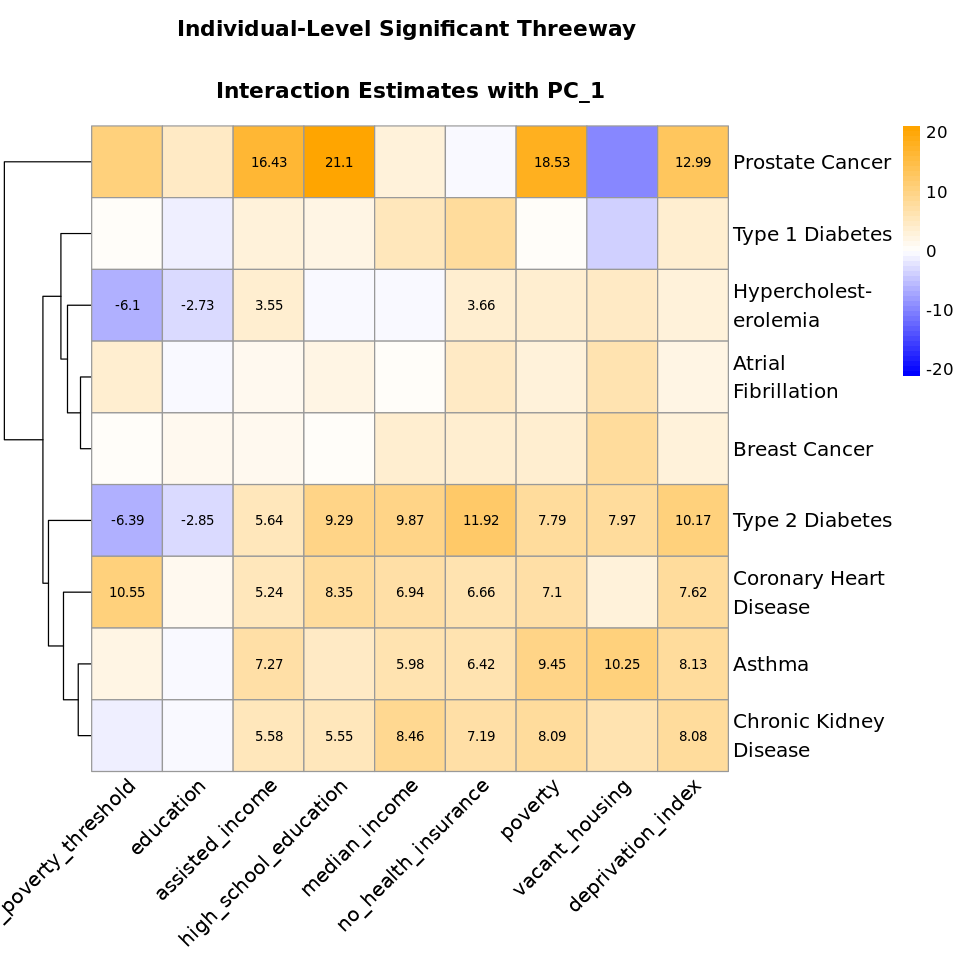

In [51]:
options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height


# Step 1: Define custom Social domain per disease

# Step 2: Join domain lookup and restrict all models to the mapped domain
auc_plot_data <- results %>%
  filter(Model == "Interaction") %>%
  filter(str_detect(term, ":PC")) %>%  # Keep terms that include ":PC"
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value) %>%
  distinct()

auc_plot_data <- auc_plot_data %>%
  mutate(PC = str_extract(term, "[^:]+$")) %>%  # extract text after last colon
  select(-term)  # remove the term column

disease_name_mapping <- c(
  "Asthma" = "Asthma",
  "Afib" = "Atrial\nFibrillation",
  "BreastC" = "Breast Cancer",
  "CKD" = "Chronic Kidney\nDisease",
  "CHD" = "Coronary Heart\nDisease", 
  "HyperC" = "Hypercholest-\nerolemia",
  "ProstateC" = "Prostate Cancer",
  "t2d" = "Type 2 Diabetes",
  "t1d" = "Type 1 Diabetes"
)

# Define column order for heatmap
x_axis_order <- c('per_poverty_threshold', 'education', 'assisted_income', 'high_school_education', 'median_income', 
                  'no_health_insurance', 'poverty', 'vacant_housing', 'deprivation_index')

auc_plot_data_PC1<-auc_plot_data|>filter(PC == "PC_1")


# Wide format for coefficients (heatmap values)
heatmap_data_ind <- auc_plot_data_PC1 %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Domain, values_from = estimate) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Wide format for p-values (mask)
pvalue_data <- auc_plot_data_PC1 %>%
  select(Disease, Domain, p.value) %>%
  pivot_wider(names_from = Domain, values_from = p.value) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Apply Bonferroni mask (significance threshold)
alpha <- 0.05 / (length(unique(results$Disease)) * length(domains))
significance_mask <- pvalue_data < alpha

# Format labels for display (only show significant values)
heatmap_labels_ind <- round(heatmap_data_ind, 2)
heatmap_labels_ind[!significance_mask] <- ""

#Rename rows to be full Disease names
rownames(heatmap_data_ind) <- disease_name_mapping[rownames(heatmap_data_ind)]

# Create diverging color palette centered on 0
max_val <- max(abs(heatmap_data_ind), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)

# Plot the heatmap
ind_map<-pheatmap(
  mat = heatmap_data_ind,
  color = palette,
  breaks = breaks,
  cluster_rows = TRUE,
  cluster_cols = FALSE,
  display_numbers = heatmap_labels_ind,
  number_color = "black",
  fontsize_row = 12,
  fontsize_col = 12,
  angle_col = 45,
  main = "Individual-Level Significant Threeway \n
Interaction Estimates with PC_1",
  width = 3,
  height = 1
)

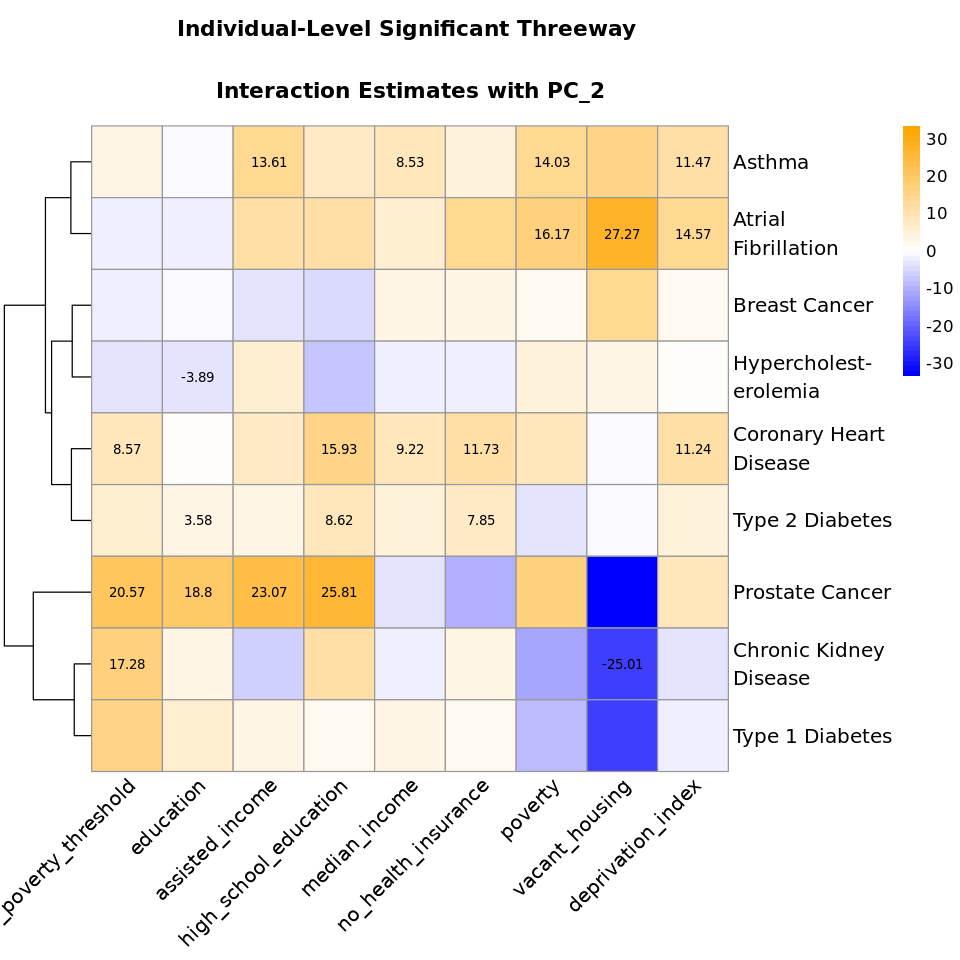

In [52]:
auc_plot_data_PC1<-auc_plot_data|>filter(PC == "PC_2")


# Wide format for coefficients (heatmap values)
heatmap_data_ind <- auc_plot_data_PC1 %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Domain, values_from = estimate) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Wide format for p-values (mask)
pvalue_data <- auc_plot_data_PC1 %>%
  select(Disease, Domain, p.value) %>%
  pivot_wider(names_from = Domain, values_from = p.value) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Apply Bonferroni mask (significance threshold)
alpha <- 0.05 / (length(unique(results$Disease)) * length(domains))
significance_mask <- pvalue_data < alpha

# Format labels for display (only show significant values)
heatmap_labels_ind <- round(heatmap_data_ind, 2)
heatmap_labels_ind[!significance_mask] <- ""

#Rename rows to be full Disease names
rownames(heatmap_data_ind) <- disease_name_mapping[rownames(heatmap_data_ind)]

# Create diverging color palette centered on 0
max_val <- max(abs(heatmap_data_ind), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)

# Plot the heatmap
ind_map<-pheatmap(
  mat = heatmap_data_ind,
  color = palette,
  breaks = breaks,
  cluster_rows = TRUE,
  cluster_cols = FALSE,
  display_numbers = heatmap_labels_ind,
  number_color = "black",
  fontsize_row = 12,
  fontsize_col = 12,
  angle_col = 45,
  main = "Individual-Level Significant Threeway \n
Interaction Estimates with PC_2",
  width = 3,
  height = 1
)

In [43]:
colnames(merged_data)

[1] "person_id"                  "Asthma_adjusted_score"     
 [3] "Afib_adjusted_score"        "BreastC_adjusted_score"    
 [5] "CKD_adjusted_score"         "CHD_adjusted_score"        
 [7] "HyperC_adjusted_score"      "ProstateC_adjusted_score"  
 [9] "t1d_adjusted_score"         "t2d_adjusted_score"        
[11] "Asthma"                     "Afib"                      
[13] "BreastC"                    "CKD"                       
[15] "CHD"                        "HyperC"                    
[17] "ProstateC"                  "t2d"                       
[19] "t1d"                        "date_of_birth"             
[21] "AIAN"                       "Asian"                     
[23] "Black"                      "Mid"                       
[25] "Multiple"                   "PI"                        
[27] "White"                      "His"                       
[29] "race_unknown"               "SexGender"                 
[31] "age_today"                  "ancestry_pred"             
[33] "PC_1"                       "PC_2"                      
[35] "PC_3"                       "PC_4"                      
[37] "PC_5"                       "PC_6"                      
[39] "PC_7"                       "PC_8"                      
[41] "PC_9"                       "PC_10"                     
[43] "PC_11"                      "PC_12"                     
[45] "PC_13"                      "PC_14"                     
[47] "PC_15"                      "PC_16"                     
[49] "where_born"                 "military"                  
[51] "healthcare"                 "disabled"                  
[53] "sexual_orientation"         "LGBTQIA"                   
[55] "min_date"                   "max_date"                  
[57] "ehr_length"                 "relative_health"           
[59] "record_depth"               "visit_frequency"           
[61] "age"                        "record_depth_winsorized"   
[63] "visit_frequency_winsorized" "education"                 
[65] "per_poverty_threshold"      "assisted_income"           
[67] "high_school_education"      "median_income"             
[69] "no_health_insurance"        "poverty"                   
[71] "vacant_housing"             "deprivation_index"         
[73] "age2"                       "SexGenderCis_male"         
[75] "SexGenderCis_female"        "SexGenderSGM"              
[77] "SIRE"

In [44]:
merged_data <- merged_data %>%
  mutate(
    SIRE = case_when(
      Black == 1 & His == 0 ~ "NH Black",
      White == 1 & His == 0 ~ "NH White",
      His == 1 ~ "HS",
      TRUE ~ "Underrepresented"
    )
  )

merged_data %>%
  group_by(SIRE) %>%
  summarise(mean_PC1 = mean(PC_1, na.rm = TRUE))


SIRE,mean_PC1
<chr>,<dbl>
HS,0.02767963
NH Black,-0.24726242
NH White,0.09787748
Underrepresented,0.04376927


In [45]:
install.packages("effects")
library(effects)

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)



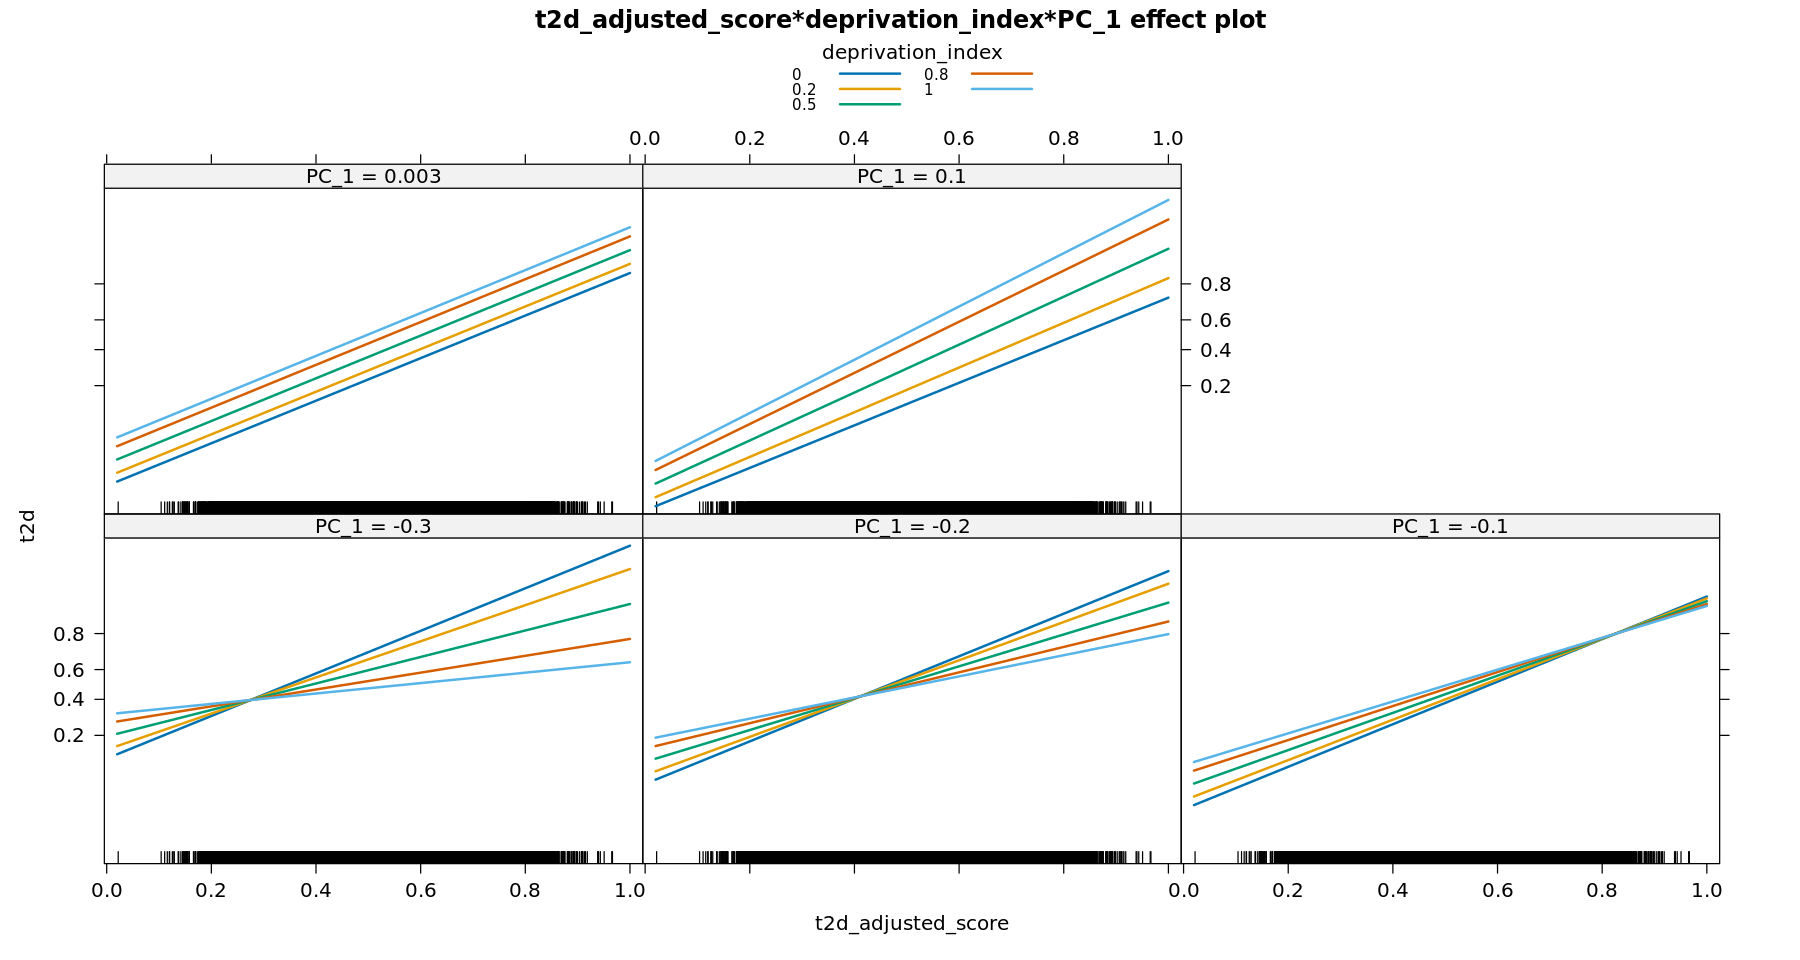

In [46]:
options(repr.plot.width = 15, repr.plot.height = 8)  # Set width and height

model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + deprivation_index + PC_1 #+ PC_2 + PC_4 + PC_5 + PC_6 + PC_7 +
           #PC_8 + PC_9 + PC_10 + PC_11 + PC_12 + PC_13 + PC_14 + PC_15 + PC_16 +
           + t2d_adjusted_score:deprivation_index:PC_1,
           data=merged_data, family=binomial)

#plot(allEffects(model), multiline = TRUE)

plot(allEffects(model)[["t2d_adjusted_score:deprivation_index:PC_1"]], multiline = TRUE)

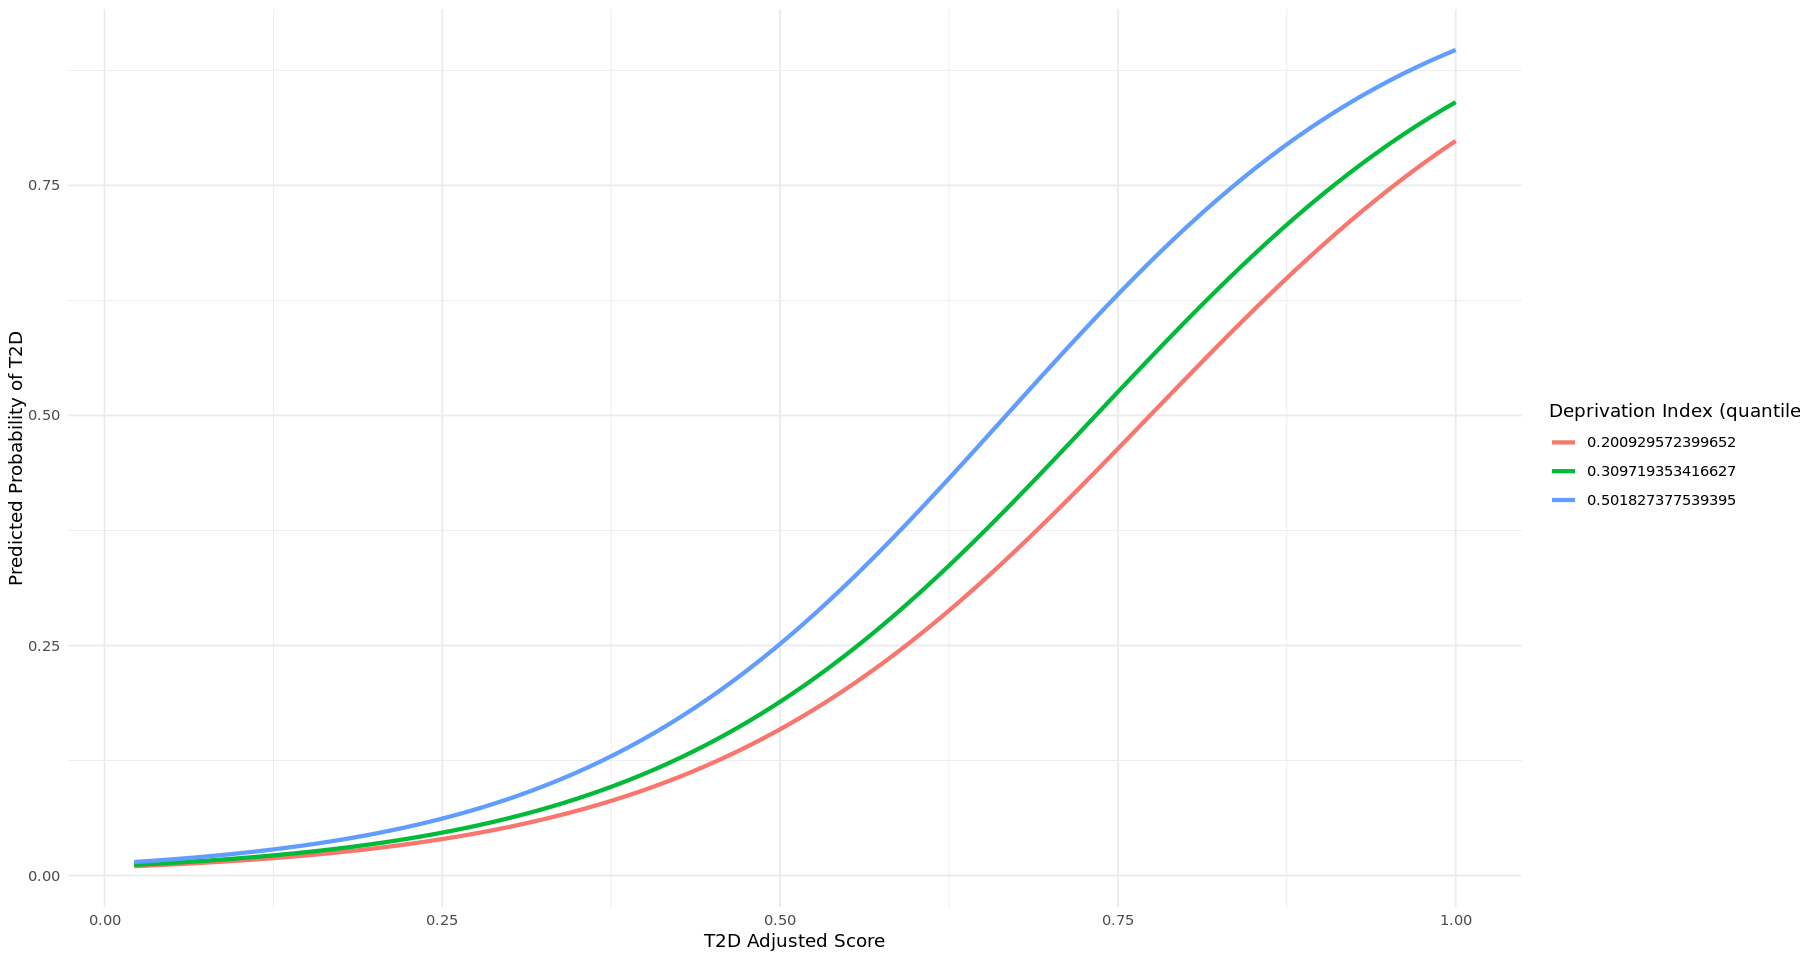

In [47]:
# 1. Create a grid of values
newdata <- expand.grid(
  t2d_adjusted_score = seq(min(merged_data$t2d_adjusted_score, na.rm = TRUE),
                           max(merged_data$t2d_adjusted_score, na.rm = TRUE),
                           length.out = 100),
  deprivation_index = quantile(merged_data$deprivation_index, probs = c(0.1, 0.5, 0.9), na.rm = TRUE),
  PC_1 = median(merged_data$PC_1, na.rm = TRUE),
  age = mean(merged_data$age, na.rm = TRUE),
  record_depth = mean(merged_data$record_depth, na.rm = TRUE),
  visit_frequency = mean(merged_data$visit_frequency, na.rm = TRUE),
  SexGenderCis_male = 0,
  SexGenderSGM = 0
)

# 2. Predict probabilities from the model
newdata$pred <- predict(model, newdata = newdata, type = "response")

# 3. Plot predicted probabilities by score, colored by deprivation
library(ggplot2)

ggplot(newdata, aes(x = t2d_adjusted_score, y = pred, color = as.factor(deprivation_index))) +
  geom_line(size = 1.2) +
  labs(
    x = "T2D Adjusted Score",
    y = "Predicted Probability of T2D",
    color = "Deprivation Index (quantiles)"
  ) +
  theme_minimal()


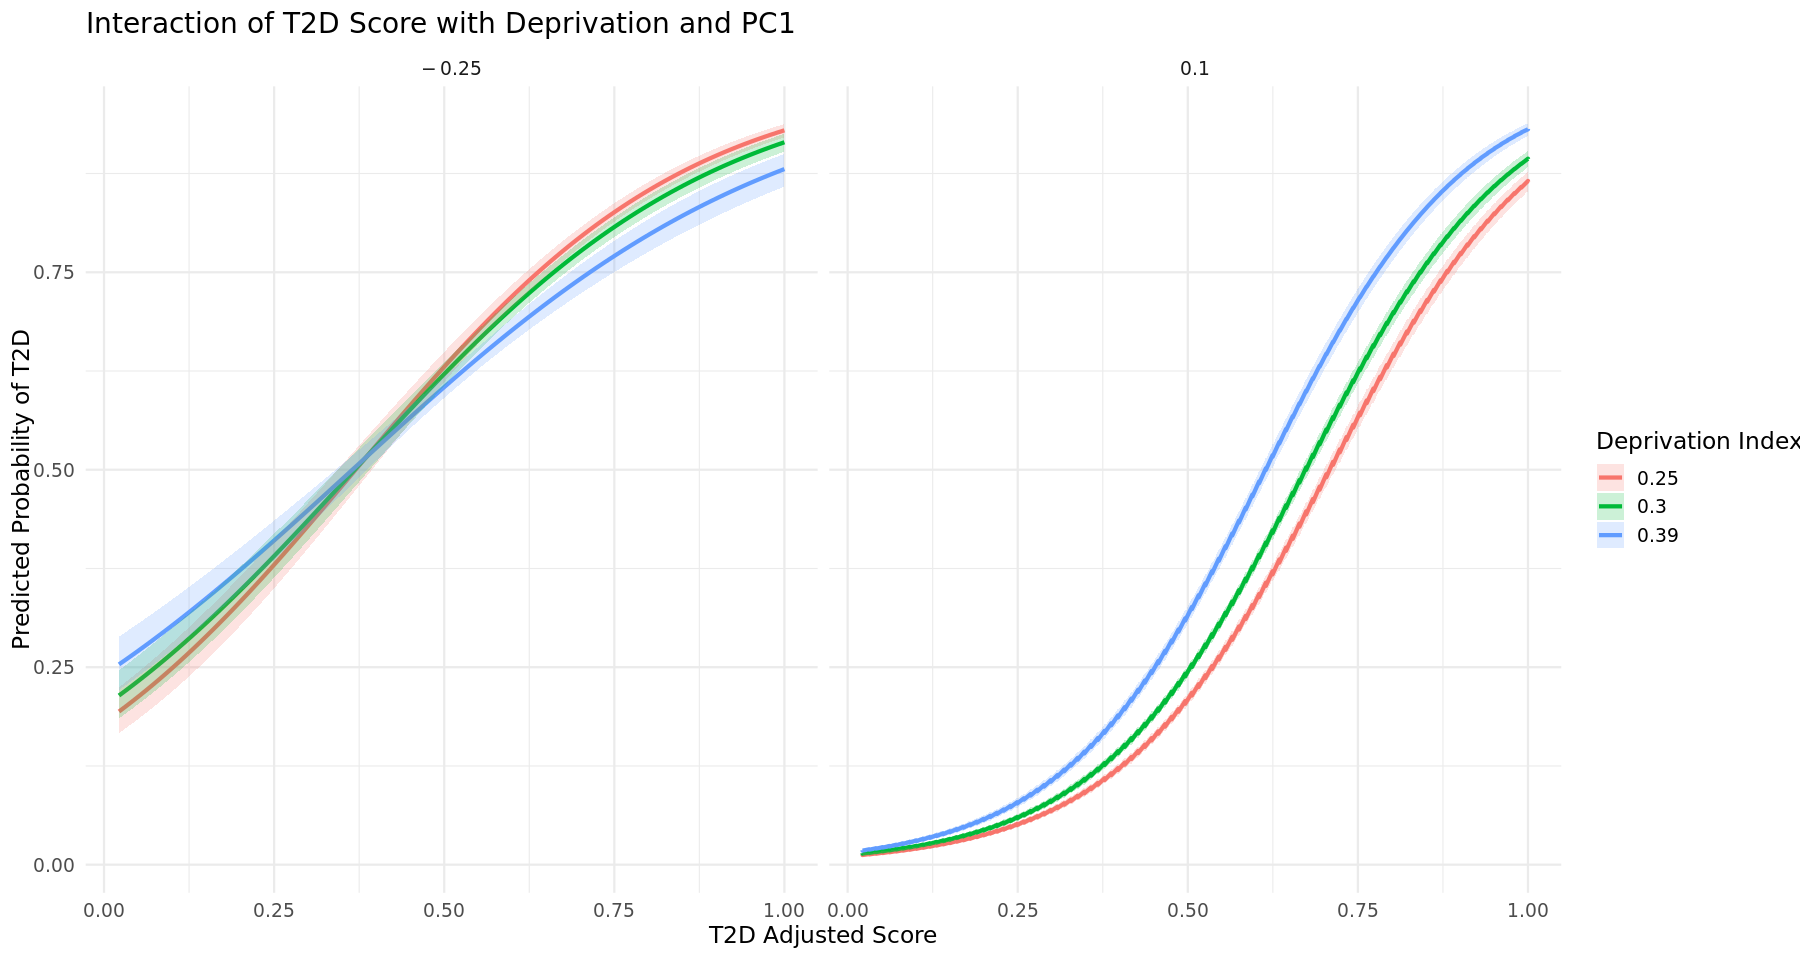

In [24]:
 library(dplyr)
library(ggplot2)

# 1. Create a grid of values
newdata <- expand.grid(
  t2d_adjusted_score = seq(min(merged_data$t2d_adjusted_score, na.rm = TRUE),
                           max(merged_data$t2d_adjusted_score, na.rm = TRUE),
                           length.out = 100),
  deprivation_index = quantile(merged_data$deprivation_index, probs = c(0.1, 0.5, 0.9), na.rm = TRUE),
  PC_1 = quantile(merged_data$PC_1, probs = c(0.1, 0.5, 0.9), na.rm = TRUE),
  age = mean(merged_data$age, na.rm = TRUE),
  record_depth = mean(merged_data$record_depth, na.rm = TRUE),
  visit_frequency = mean(merged_data$visit_frequency, na.rm = TRUE),
  SexGenderCis_male = 1,
  SexGenderSGM = 0
)

# 2. Predict probabilities and standard errors
pred <- predict(model, newdata = newdata, type = "link", se.fit = TRUE)

# Add predicted probabilities and confidence intervals to grid
newdata <- newdata %>%
  mutate(
    fit_link = pred$fit,
    se_link = pred$se.fit,
    pred_prob = plogis(fit_link),  # inverse logit to get probability
    lower_ci = plogis(fit_link - 1.96 * se_link),
    upper_ci = plogis(fit_link + 1.96 * se_link),
    deprivation_index = as.factor(round(deprivation_index, 2)),
    PC_1 = as.factor(round(PC_1, 2))  # Convert to factor for facetting
  )

# 3. Plot with confidence ribbons and facets for PC_1
ggplot(newdata, aes(x = t2d_adjusted_score, y = pred_prob, color = deprivation_index, fill = deprivation_index)) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = lower_ci, ymax = upper_ci), alpha = 0.2, color = NA) +
  facet_wrap(~ PC_1, labeller = label_parsed) +
  labs(
    x = "T2D Adjusted Score",
    y = "Predicted Probability of T2D",
    color = "Deprivation Index",
    fill = "Deprivation Index",
    title = "Interaction of T2D Score with Deprivation and PC1"
  ) +
  theme_minimal(base_size = 14)


In [23]:
# List of all PCs to test for interaction
pcs_to_test <- paste0("PC_", c(1:16))  # adjust as needed

# Define your base formula (no interactions)
base_formula <- as.formula("t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
                            t2d_adjusted_score + assisted_income + high_school_education + median_income +  
                            no_health_insurance + poverty + vacant_housing + deprivation_index")

# Fit initial model
current_formula <- base_formula
current_model <- glm(current_formula, data = merged_data, family = binomial)

# Store included significant interactions
included_interactions <- c()

# Loop through each PC and test interaction
for (pc in pcs_to_test) {
  new_formula <- update(current_formula, paste(". ~ . +", pc))
  new_model <- glm(new_formula, data = merged_data, family = binomial)
  
  # Likelihood Ratio Test
  lrt <- anova(current_model, new_model, test = "LRT")
  pval <- lrt$`Pr(>Chi)`[2]  # get p-value for added interaction
  
  if (!is.na(pval) && pval < 0.05) {
    message(pc, ": Significant (p = ", round(pval, 5), "), adding to model")
    current_formula <- new_formula
    current_model <- new_model
  } else {
    message(pc, ": Not significant (p = ", round(pval, 5), "), skipping")
  }
}

# Final model summary
summary(current_model)

# Optional: see final formula
cat("\nFinal formula:\n")
print(current_formula)
final_formula1<-current_model

# Optional: print included interaction terms
cat("\nSignificant interactions included:\n")
print(included_interactions)


PC_1: Significant (p = 0), adding to model

PC_2: Significant (p = 0), adding to model

PC_3: Significant (p = 0), adding to model

PC_4: Significant (p = 0), adding to model

PC_5: Significant (p = 0.00122), adding to model

PC_6: Not significant (p = 0.81961), skipping

PC_7: Not significant (p = 0.88986), skipping

PC_8: Not significant (p = 0.44962), skipping

PC_9: Not significant (p = 0.46352), skipping

PC_10: Not significant (p = 0.7537), skipping

PC_11: Not significant (p = 0.84718), skipping

PC_12: Not significant (p = 0.73439), skipping

PC_13: Not significant (p = 0.13553), skipping

PC_14: Significant (p = 0.04175), adding to model

PC_15: Not significant (p = 0.52334), skipping

PC_16: Not significant (p = 0.13391), skipping




Call:
glm(formula = new_formula, family = binomial, data = merged_data)

Coefficients: (1 not defined because of singularities)
                        Estimate Std. Error z value Pr(>|z|)    
(Intercept)           -7.698e+00  8.876e-02 -86.725  < 2e-16 ***
age                    4.897e-02  7.066e-04  69.300  < 2e-16 ***
record_depth           1.487e-03  6.964e-05  21.352  < 2e-16 ***
visit_frequency        4.577e+00  3.959e-01  11.561  < 2e-16 ***
SexGenderCis_male      3.463e-01  1.992e-02  17.387  < 2e-16 ***
SexGenderSGM           2.746e-01  6.127e-02   4.481 7.42e-06 ***
t2d_adjusted_score     5.768e+00  9.288e-02  62.101  < 2e-16 ***
assisted_income       -2.555e+00  1.504e-01 -16.987  < 2e-16 ***
high_school_education  1.663e+00  1.279e-01  13.003  < 2e-16 ***
median_income          2.129e+00  1.108e-01  19.217  < 2e-16 ***
no_health_insurance   -4.372e-01  9.487e-02  -4.609 4.05e-06 ***
poverty                1.229e-01  1.825e-01   0.673  0.50072    
vacant_housing         9.6


Final formula:
t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + 
    SexGenderSGM + t2d_adjusted_score + assisted_income + high_school_education + 
    median_income + no_health_insurance + poverty + vacant_housing + 
    deprivation_index + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_14

Significant interactions included:
NULL


In [24]:
# List of all PCs to test for interaction
pcs_to_test <- paste0("PC_", c(1:16))  # adjust as needed

# Define your base formula (no interactions)
base_formula <- as.formula("t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
                            t2d_adjusted_score + assisted_income + high_school_education + median_income +  
                            no_health_insurance + poverty + vacant_housing + deprivation_index + 
                            PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_14")

# Fit initial model
current_formula <- base_formula
current_model <- glm(current_formula, data = merged_data, family = binomial)

# Store included significant interactions
included_interactions <- c()

# Loop through each PC and test interaction
for (pc in pcs_to_test) {
  interaction_term <- paste0("t2d_adjusted_score:deprivation_index:", pc)
  new_formula <- update(current_formula, paste(". ~ . +", interaction_term))
  new_model <- glm(new_formula, data = merged_data, family = binomial)
  
  # Likelihood Ratio Test
  lrt <- anova(current_model, new_model, test = "LRT")
  pval <- lrt$`Pr(>Chi)`[2]  # get p-value for added interaction
  
  if (!is.na(pval) && pval < 0.05) {
    message(pc, ": Significant (p = ", round(pval, 5), "), adding to model")
    current_formula <- new_formula
    current_model <- new_model
    included_interactions <- c(included_interactions, interaction_term)
  } else {
    message(pc, ": Not significant (p = ", round(pval, 5), "), skipping")
  }
}

# Final model summary
summary(current_model)

# Optional: see final formula
cat("\nFinal formula:\n")
final_formula<-current_formula
print(current_formula)

# Optional: print included interaction terms
cat("\nSignificant interactions included:\n")
print(included_interactions)


PC_1: Significant (p = 0), adding to model

PC_2: Significant (p = 0.02452), adding to model

PC_3: Significant (p = 0.02349), adding to model

PC_4: Significant (p = 0.04622), adding to model

PC_5: Significant (p = 4e-05), adding to model

PC_6: Not significant (p = 0.0748), skipping

PC_7: Not significant (p = 0.16335), skipping

PC_8: Not significant (p = 0.96256), skipping

PC_9: Not significant (p = 0.61516), skipping

PC_10: Not significant (p = 0.94522), skipping

PC_11: Not significant (p = 0.96683), skipping

PC_12: Not significant (p = 0.8297), skipping

PC_13: Not significant (p = 0.21034), skipping

PC_14: Not significant (p = 0.80967), skipping

PC_15: Not significant (p = 0.63526), skipping

PC_16: Not significant (p = 0.20319), skipping




Call:
glm(formula = new_formula, family = binomial, data = merged_data)

Coefficients: (1 not defined because of singularities)
                                            Estimate Std. Error z value
(Intercept)                               -7.355e+00  1.368e-01 -53.744
age                                        4.920e-02  7.076e-04  69.530
record_depth                               1.490e-03  6.987e-05  21.325
visit_frequency                            4.545e+00  3.970e-01  11.449
SexGenderCis_male                          3.492e-01  1.995e-02  17.509
SexGenderSGM                               2.705e-01  6.132e-02   4.411
t2d_adjusted_score                         5.548e+00  1.352e-01  41.049
assisted_income                           -2.216e+00  1.570e-01 -14.112
high_school_education                      1.481e+00  1.321e-01  11.210
median_income                              1.808e+00  1.184e-01  15.272
no_health_insurance                       -5.587e-01  9.978e-02  -5.599
poverty


Final formula:
t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + 
    SexGenderSGM + t2d_adjusted_score + assisted_income + high_school_education + 
    median_income + no_health_insurance + poverty + vacant_housing + 
    deprivation_index + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_14 + 
    t2d_adjusted_score:deprivation_index:PC_1 + t2d_adjusted_score:deprivation_index:PC_2 + 
    t2d_adjusted_score:deprivation_index:PC_3 + t2d_adjusted_score:deprivation_index:PC_4 + 
    t2d_adjusted_score:deprivation_index:PC_5

Significant interactions included:
[1] "t2d_adjusted_score:deprivation_index:PC_1"
[2] "t2d_adjusted_score:deprivation_index:PC_2"
[3] "t2d_adjusted_score:deprivation_index:PC_3"
[4] "t2d_adjusted_score:deprivation_index:PC_4"
[5] "t2d_adjusted_score:deprivation_index:PC_5"


In [25]:
# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain, model, PC) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  #interaction <- paste0(score, ":", domain, ":", PC)
  domains<-c('assisted_income', 'high_school_education', 'median_income', 'no_health_insurance',
           'poverty', 'vacant_housing', 'deprivation_index')
  domain <- paste(domains, collapse = " + ")

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", paste(base, collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, domain), collapse = " + "))),  
    as.formula(final_formula1),
    as.formula(final_formula)
  )
}

In [26]:
# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain, model=NULL)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results)

Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
t2d,deprivation_index,Base,(Intercept),-3.1406765883,3.760081e-02,-83.526825,0.000000e+00,0.6982797,0.6942504,0.702309
t2d,deprivation_index,Base,age,0.0344355472,6.001864e-04,57.374756,0.000000e+00,0.6982797,0.6942504,0.702309
t2d,deprivation_index,Base,record_depth,0.0009688634,6.071282e-05,15.958136,2.500914e-57,0.6982797,0.6942504,0.702309
t2d,deprivation_index,Base,visit_frequency,4.8247033974,3.608377e-01,13.370840,8.952374e-41,0.6982797,0.6942504,0.702309
t2d,deprivation_index,Base,SexGenderCis_male,0.2483163669,1.814420e-02,13.685719,1.235785e-42,0.6982797,0.6942504,0.702309
t2d,deprivation_index,Base,SexGenderSGM,0.2860814830,5.557668e-02,5.147509,2.639680e-07,0.6982797,0.6942504,0.702309


In [27]:
# Step 2: Join domain lookup and restrict all models to the mapped domain
auc_plot_data <- results %>%
  filter(Model %in% c("Base", "Genetic", "Social", "Joint", "Interaction")) %>%
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, Model, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()

In [28]:
auc_plot_data

Disease,Domain,Model,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
t2d,deprivation_index,Base,0.6982797,0.6942504,0.7023090
t2d,deprivation_index,Genetic,0.7478621,0.7440482,0.7516759
t2d,deprivation_index,Social,0.7249561,0.7210573,0.7288550
t2d,deprivation_index,Joint,0.7990471,0.7956176,0.8024766
t2d,deprivation_index,Interaction,0.7999480,0.7965224,0.8033735


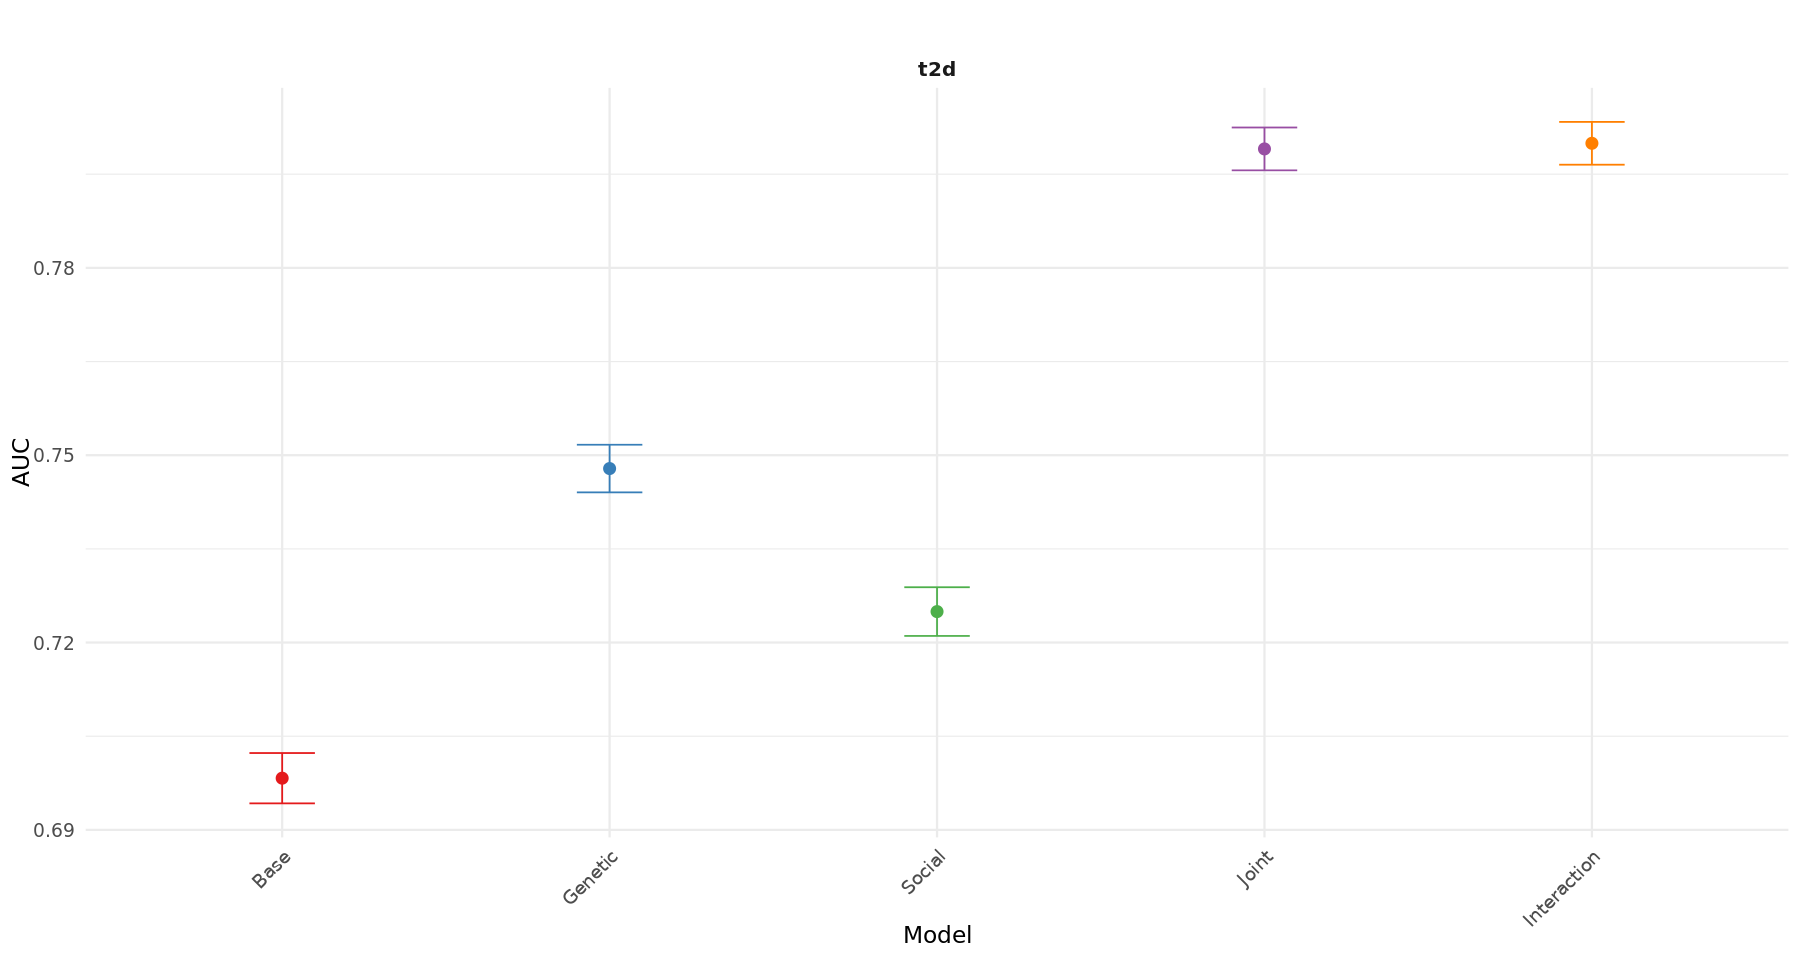

In [29]:
auc_plot_data$Disease <- factor(auc_plot_data$Disease, levels = 
                                c(
                                  "ProstateC", "t1d", "CKD", 
                                  "Afib", "BreastC",  "CHD",
                                 "t2d", "Asthma")) 


auc_plot_data$Model <- factor(auc_plot_data$Model, levels = 
                                c("Base", "Genetic", "Social",
                                    "Joint", "Interaction"))  

# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = Model, y = AUC, color = Model)) +
  geom_point(position = position_dodge(width = 0.5), size = 3) +  # Points for AUC
  geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper), 
                position = position_dodge(width = 0.5), width = 0.2) +  # Error bars for 95% CI
  facet_wrap(~ Disease, scales = "free_y", ncol = 3) +  # Adjust the number of columns to make the figure wider
  scale_color_brewer(palette = "Set1", name = "Model") +  # Color by Model
  labs(
    title = " ",
    x = "Model",
    y = "AUC"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5)
  ) + theme(legend.position="none")

# Set plot size for Jupyter Notebook
options(repr.plot.width = 15, repr.plot.height = 8)  # Set width and height
print(auc_plot)

# Save the plot (optional)
ggsave("auc_plot_with_ci.png", plot = auc_plot, width = 15, height = 8, dpi = 300)

In [30]:
#install.packages("interactions")
#library(interactions)
interact_plot(model, pred = t2d_adjusted_score, modx = deprivation_index, mod2 = PC_1, 
              plot.points = FALSE, interval = TRUE, scale = TRUE, n.sd =2, int.width = 0.95)

ERROR: Error in interact_plot(model, pred = t2d_adjusted_score, modx = deprivation_index, : could not find function "interact_plot"
